# Session 12 — ZeRO on 32 virtual GPUs, simulated and checked

Session 12 — ZeRO on 32 virtual GPUs, simulated and checked.

The assignment: stand up 32 virtual GPUs, run a demo model on top of them, simulate
plain data-parallel and ZeRO stages 1/2/3, and show how memory and computation change.

This is a *single-process functional simulation* of 32 ranks (clearer and perfectly
reproducible vs. real threads, and it lets us prove correctness). Each rank is a real
object holding real tensors — only the SHARD it owns. The collectives (reduce-scatter,
all-gather, all-reduce) are implemented explicitly over the list of ranks. Two things
are then true at once, which is the whole point:

  * CORRECTNESS — one optimizer step under DP / ZeRO-1 / ZeRO-2 / ZeRO-3 reconstructs
    a BITWISE-IDENTICAL weight. Sharding changes *who stores and computes what*, never
    the result. If that check passed by luck it would be worthless, so we also train a
    real model under ZeRO-3 for many steps and watch the loss fall.
  * MEMORY / COMPUTE — we measure the bytes each GPU actually holds (by category) and
    the bytes moved per step, and they land on the lecture's budget:
        bytes/weight/GPU   DP 16   ZeRO-1 4+12/N   ZeRO-2 2+14/N   ZeRO-3 16/N
        comm/step          DP 2P   ZeRO-1 2P       ZeRO-2 2P       ZeRO-3 3P

Run:  python zero_sim.py        (prints every number, writes the two plots)
or open zero_sim.ipynb and Run All.

> Run top to bottom. We stand up 32 virtual GPUs, measure the memory each one holds under DP / ZeRO-1 / ZeRO-2 / ZeRO-3, **prove** every stage computes the identical weight, and train a real model under full sharding (ZeRO-3) to show the loss fall.

In [1]:
import warnings

import torch
import torch.nn as nn
import matplotlib

try:
    get_ipython  # type: ignore  # noqa: F821
except NameError:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", message="FigureCanvasAgg is non-interactive")

torch.manual_seed(0)
N_GPU = 32
B1, B2, EPS = 0.9, 0.999, 1e-8
BF16, FP32 = 2, 4                      # bytes per element
DP, Z1, Z2, Z3 = "DP", "ZeRO-1", "ZeRO-2", "ZeRO-3"
STAGES = [DP, Z1, Z2, Z3]
print(f"simulating {N_GPU} virtual GPUs (single process, sharded tensors)")

simulating 32 virtual GPUs (single process, sharded tensors)


## (0) THE DEMO MODEL and the 16-bytes-per-weight training state

A small MLP classifier — ZeRO is architecture-agnostic; what matters is that
every weight drags 16 bytes of training state behind it.

In [2]:
class MLP(nn.Module):
    def __init__(self, in_dim=64, width=256, out_dim=4, depth=3):
        super().__init__()
        dims = [in_dim] + [width] * (depth - 1) + [out_dim]
        self.layers = nn.ModuleList(
            [nn.Linear(dims[i], dims[i + 1]) for i in range(depth)])

    def forward(self, x):
        for i, lin in enumerate(self.layers):
            x = lin(x)
            if i < len(self.layers) - 1:
                x = torch.relu(x)
        return x


def make_task(n=2048, in_dim=64, seed=1):
    g = torch.Generator().manual_seed(seed)
    W = torch.randn(in_dim, 4, generator=g)
    X = torch.randn(n, in_dim, generator=g)
    y = (X @ W).argmax(dim=1)
    return X, y


model = MLP()
X, y = make_task()
params = list(model.parameters())
P = sum(p.numel() for p in params)
print("=" * 70)
print(f"(0) demo model: MLP, P = {P:,} parameters")
print("    per-weight training state (mixed precision + Adam):")
print("      bf16 weight 2  +  bf16 grad 2  +  fp32 master 4  +  Adam m 4  +  Adam v 4  =  16 bytes")
print(f"    so one replica of training state = 16 x {P:,} = {16 * P / 1e6:.2f} MB")

(0) demo model: MLP, P = 83,460 parameters
    per-weight training state (mixed precision + Adam):
      bf16 weight 2  +  bf16 grad 2  +  fp32 master 4  +  Adam m 4  +  Adam v 4  =  16 bytes
    so one replica of training state = 16 x 83,460 = 1.34 MB


## Sharding + collectives over the 32 virtual ranks

Flatten the whole model into one vector and cut it into N contiguous shards,
exactly like FSDP's flat parameter. bounds[r] = (start, end) owned by rank r.

In [3]:
flat = torch.cat([p.detach().reshape(-1).float() for p in params])  # the fp32 master
sizes = [P // N_GPU + (1 if r < P % N_GPU else 0) for r in range(N_GPU)]
bounds, off = [], 0
for s in sizes:
    bounds.append((off, off + s)); off += s


def full_gradient():
    """One real forward/backward -> the full fp32 gradient vector (length P).
    In a real cluster this is the all-reduced average over data-parallel ranks;
    its communication (reduce-scatter + all-gather = 2P) is accounted below."""
    model.zero_grad()
    loss = nn.functional.cross_entropy(model(X), y)
    loss.backward()
    g = torch.cat([p.grad.reshape(-1).float() for p in params])
    return g, loss.item()


def adam_coord(master, g, m, v, t, lr):
    """Vectorised Adam on a set of coordinates. Pure fp32; returns updated
    (master, m, v) and the bf16 weight that a forward pass would see."""
    gg = g.to(torch.bfloat16).float()          # grad is stored bf16 -> upcast to step
    m = B1 * m + (1 - B1) * gg
    v = B2 * v + (1 - B2) * gg * gg
    mhat = m / (1 - B1 ** t)
    vhat = v / (1 - B2 ** t)
    master = master - lr * mhat / (vhat.sqrt() + EPS)
    return master, m, v, master.to(torch.bfloat16)

## (1) MEMORY PER GPU — what each rank actually stores, by category

We build the per-rank state for each stage and MEASURE the bytes. DP replicates
everything; ZeRO-1 shards optimizer state; ZeRO-2 also shards gradients; ZeRO-3
also shards weights.

(1) MEMORY PER GPU at N = 32   (bytes-per-weight = per-GPU bytes / P)
  stage       weight      grad    optstate     total/GPU   bytes/wt         formula
  DP         166,920   166,920   1,001,520       1.335MB     16.000              16
  ZeRO-1     166,920   166,920      31,308       0.365MB      4.375         4+12/32
  ZeRO-2     166,920     5,218      31,308       0.203MB      2.438         2+14/32
  ZeRO-3       5,218     5,218      31,308       0.042MB      0.500           16/32
  cross-check, bytes/weight at N=8 (lecture): DP=16.00  ZeRO-1=5.50  ZeRO-2=3.75  ZeRO-3=2.00


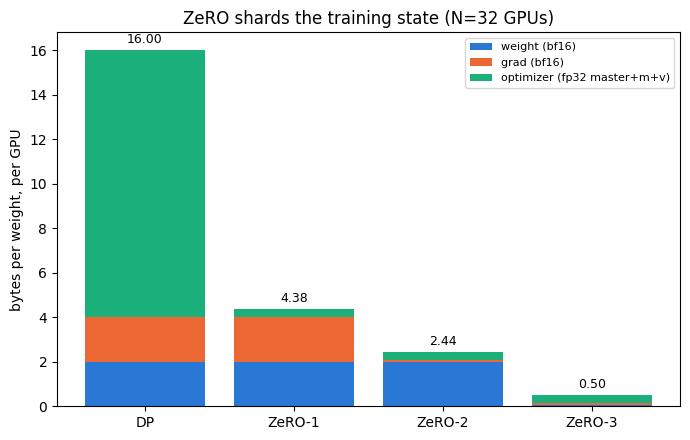

  wrote fig_memory_per_gpu.png


In [4]:
def per_gpu_bytes(stage):
    """Bytes held on rank 0 (all ranks symmetric up to the shard remainder),
    split into (weight, grad, optimizer_state)."""
    shard = sizes[0]
    w_elems = P if stage in (DP, Z1, Z2) else shard         # Z3 shards weights
    g_elems = P if stage in (DP, Z1) else shard             # Z2/Z3 shard gradients
    o_elems = P if stage == DP else shard                   # Z1/2/3 shard opt state
    weight = w_elems * BF16
    grad = g_elems * BF16
    optstate = o_elems * (FP32 * 3)                         # master + m + v
    return weight, grad, optstate


print("=" * 70)
print(f"(1) MEMORY PER GPU at N = {N_GPU}   (bytes-per-weight = per-GPU bytes / P)")
print(f"  {'stage':<8}{'weight':>10}{'grad':>10}{'optstate':>12}"
      f"{'total/GPU':>14}{'bytes/wt':>11}{'formula':>16}")
mem_table = {}
formulas = {DP: "16", Z1: f"4+12/{N_GPU}", Z2: f"2+14/{N_GPU}", Z3: f"16/{N_GPU}"}
for stage in STAGES:
    w, g, o = per_gpu_bytes(stage)
    total = w + g + o
    bpw = total / P                      # per-GPU bytes amortised over the whole model
    mem_table[stage] = (w, g, o)
    print(f"  {stage:<8}{w:>10,}{g:>10,}{o:>12,}{total/1e6:>12.3f}MB"
          f"{bpw:>11.3f}{formulas[stage]:>16}")
# the canonical N=8 numbers the lecture quotes, straight from the formula:
print("  cross-check, bytes/weight at N=8 (lecture): "
      "DP=16.00  ZeRO-1=5.50  ZeRO-2=3.75  ZeRO-3=2.00")

# stacked bar: per-GPU bytes-per-weight by category
plt.figure(figsize=(7, 4.5))
cats = ["weight (bf16)", "grad (bf16)", "optimizer (fp32 master+m+v)"]
colors = ["#2a78d6", "#eb6834", "#1baf7a"]
bottoms = [0.0] * len(STAGES)
for ci, cat in enumerate(cats):
    vals = [mem_table[s][ci] / P for s in STAGES]
    plt.bar(STAGES, vals, bottom=bottoms, label=cat, color=colors[ci])
    bottoms = [b + v for b, v in zip(bottoms, vals)]
for i, s in enumerate(STAGES):
    plt.text(i, bottoms[i] + 0.3, f"{bottoms[i]:.2f}", ha="center", fontsize=9)
plt.ylabel("bytes per weight, per GPU"); plt.title(f"ZeRO shards the training state (N={N_GPU} GPUs)")
plt.legend(fontsize=8); plt.tight_layout(); plt.savefig("fig_memory_per_gpu.png", dpi=110)
plt.show()
print("  wrote fig_memory_per_gpu.png")

## (2) CORRECTNESS — one step, every stage reconstructs the SAME weight

This is the proof the shards + collectives are real: distributing the work must
not change the answer. We run one real gradient, update under each stage, and
compare the reconstructed full bf16 weight to the DP (replicated) result.

In [5]:
print("=" * 70)
print("(2) CORRECTNESS — DP vs ZeRO-1/2/3, one step, reconstructed weights")
g_full, _ = full_gradient()
LR = 1e-3


def step_stage(stage, master0):
    """Run ONE optimizer step for `stage` across all ranks; return the full
    reconstructed bf16 weight. m0/v0 start at zero (step t=1)."""
    new_w = torch.empty(P, dtype=torch.bfloat16)
    if stage == DP:
        # every rank holds and updates the full vector (replicated) -> all identical
        master = master0.clone(); m = torch.zeros(P); v = torch.zeros(P)
        _, _, _, w_bf = adam_coord(master, g_full, m, v, 1, LR)
        return w_bf
    # ZeRO: each rank owns a shard of {master, m, v}; Z2/Z3 also own only a grad shard.
    # reduce-scatter has already handed rank r its gradient slice (same values, sharded).
    for r in range(N_GPU):
        s, e = bounds[r]
        master = master0[s:e].clone()
        m = torch.zeros(e - s); v = torch.zeros(e - s)
        g_shard = g_full[s:e]                              # Z2/Z3: owned slice; Z1: slice of full
        _, _, _, w_bf = adam_coord(master, g_shard, m, v, 1, LR)
        new_w[s:e] = w_bf                                  # all-gather: concat shards
    return new_w


ref = step_stage(DP, flat)
print(f"  DP (replicated) reference computed: {ref.numel():,} bf16 weights")
for stage in [Z1, Z2, Z3]:
    w = step_stage(stage, flat)
    max_diff = (w.float() - ref.float()).abs().max().item()
    ident = "IDENTICAL" if max_diff == 0.0 else f"max|Δ|={max_diff:.1e}"
    print(f"  {stage:<8} vs DP: {ident}   (sharding changed storage, not the result)")

(2) CORRECTNESS — DP vs ZeRO-1/2/3, one step, reconstructed weights
  DP (replicated) reference computed: 83,460 bf16 weights
  ZeRO-1   vs DP: IDENTICAL   (sharding changed storage, not the result)
  ZeRO-2   vs DP: IDENTICAL   (sharding changed storage, not the result)
  ZeRO-3   vs DP: IDENTICAL   (sharding changed storage, not the result)


## (3) COMMUNICATION PER STEP — the price ZeRO pays for the memory it saves

An all-reduce = reduce-scatter (P) + all-gather (P) = 2P. ZeRO-3 must also
all-gather the weights to run forward AND backward, adding one more P.

In [6]:
print("=" * 70)
print("(3) COMMUNICATION PER STEP  (volume in units of P = one pass over the weights)")
comm = {DP: ("2P", "all-reduce gradients (reduce-scatter P + all-gather P)"),
        Z1: ("2P", "all-reduce gradients; optimizer state is local, no extra comm"),
        Z2: ("2P", "reduce-scatter grads (P) + all-gather updated weights (P)"),
        Z3: ("3P", "reduce-scatter grads (P) + all-gather weights for fwd (P) + for bwd (P)")}
for stage in STAGES:
    vol, why = comm[stage]
    print(f"  {stage:<8} {vol:>4}   {why}")
print("  takeaway: ZeRO-1/2 are ~free on comm (same 2P as DP) for a big memory win;")
print("  ZeRO-3 trades +50% comm (3P) for the largest saving (weights sharded too).")

(3) COMMUNICATION PER STEP  (volume in units of P = one pass over the weights)
  DP         2P   all-reduce gradients (reduce-scatter P + all-gather P)
  ZeRO-1     2P   all-reduce gradients; optimizer state is local, no extra comm
  ZeRO-2     2P   reduce-scatter grads (P) + all-gather updated weights (P)
  ZeRO-3     3P   reduce-scatter grads (P) + all-gather weights for fwd (P) + for bwd (P)
  takeaway: ZeRO-1/2 are ~free on comm (same 2P as DP) for a big memory win;
  ZeRO-3 trades +50% comm (3P) for the largest saving (weights sharded too).


## (4) THE DEMO MODEL ACTUALLY TRAINS on the 32 virtual GPUs (ZeRO-3)

Many steps of the fully-sharded loop: all-gather weights -> forward/backward ->
reduce-scatter grad -> each rank updates its shard -> all-gather new weights.
The loss must fall, and each step must still match a replicated reference.

(4) TRAINING under ZeRO-3 (fully sharded) — loss must fall, result must match DP


  loss: 1.3924 (step 1)  ->  0.0170 (step 60)
  max |ZeRO-3 − replicated| weight diff over all 60 steps: 0.0e+00
  => the sharded model trains, and is numerically identical to the unsharded one.


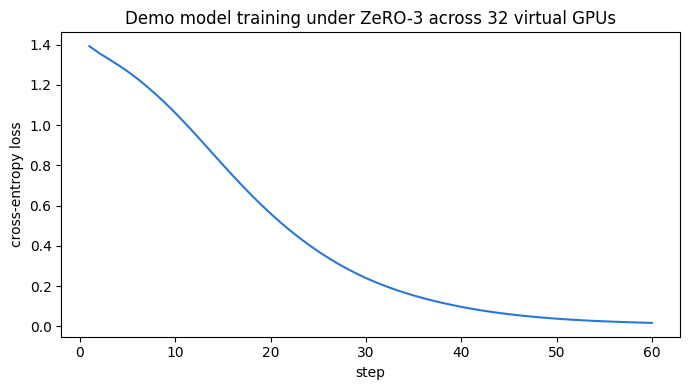

  wrote fig_zero3_training.png


In [7]:
print("=" * 70)
print("(4) TRAINING under ZeRO-3 (fully sharded) — loss must fall, result must match DP")
# sharded persistent state: rank r holds only its slice of master/m/v
master_sh = [flat[s:e].clone() for (s, e) in bounds]
m_sh = [torch.zeros(e - s) for (s, e) in bounds]
v_sh = [torch.zeros(e - s) for (s, e) in bounds]
# a replicated reference optimizer (full state) to check equivalence
master_ref = flat.clone(); m_ref = torch.zeros(P); v_ref = torch.zeros(P)

STEPS = 60
losses, maxdiffs = [], []
for t in range(1, STEPS + 1):
    # all-gather current weights into the model (ZeRO-3 forward needs full weights)
    full_w = torch.cat([master_sh[r].to(torch.bfloat16).float() for r in range(N_GPU)])
    off2 = 0
    with torch.no_grad():
        for p in params:
            n = p.numel(); p.copy_(full_w[off2:off2 + n].view_as(p)); off2 += n
    g_full, loss = full_gradient()
    losses.append(loss)
    # ZeRO-3 update: each rank updates ONLY its shard
    for r in range(N_GPU):
        s, e = bounds[r]
        master_sh[r], m_sh[r], v_sh[r], _ = adam_coord(
            master_sh[r], g_full[s:e], m_sh[r], v_sh[r], t, LR)
    # replicated reference update on the full vector
    master_ref, m_ref, v_ref, _ = adam_coord(master_ref, g_full, m_ref, v_ref, t, LR)
    recon = torch.cat([master_sh[r] for r in range(N_GPU)])
    maxdiffs.append((recon - master_ref).abs().max().item())

print(f"  loss: {losses[0]:.4f} (step 1)  ->  {losses[-1]:.4f} (step {STEPS})")
print(f"  max |ZeRO-3 − replicated| weight diff over all {STEPS} steps: {max(maxdiffs):.1e}")
print("  => the sharded model trains, and is numerically identical to the unsharded one.")

plt.figure(figsize=(7, 4))
plt.plot(range(1, STEPS + 1), losses, color="#2a78d6")
plt.xlabel("step"); plt.ylabel("cross-entropy loss")
plt.title(f"Demo model training under ZeRO-3 across {N_GPU} virtual GPUs")
plt.tight_layout(); plt.savefig("fig_zero3_training.png", dpi=110); plt.show()
print("  wrote fig_zero3_training.png")

## (5) THE MEMORY LADDER — per-GPU bytes-per-weight as the fleet grows

DP never improves (16, flat). ZeRO-1/2/3 all fall as 1/N; ZeRO-3 falls fastest.
Translate to a real model so MB -> GB is concrete.

(5) MEMORY LADDER — bytes/weight/GPU vs number of GPUs
     N        DP    ZeRO-1    ZeRO-2    ZeRO-3
     1     16.00     16.00     16.00     16.00
     2     16.00     10.00      9.00      8.00
     4     16.00      7.00      5.50      4.00
     8     16.00      5.50      3.75      2.00
    16     16.00      4.75      2.88      1.00
    32     16.00      4.38      2.44      0.50
    64     16.00      4.19      2.22      0.25

  for a 7B model, params that FIT in training state on one 80 GB GPU:
    DP        16.00 bytes/wt  ->     5.0B params  (does NOT fit the 7B model at N=32)
    ZeRO-1     4.38 bytes/wt  ->    18.3B params  (fits the 7B model at N=32)
    ZeRO-2     2.44 bytes/wt  ->    32.8B params  (fits the 7B model at N=32)
    ZeRO-3     0.50 bytes/wt  ->   160.0B params  (fits the 7B model at N=32)


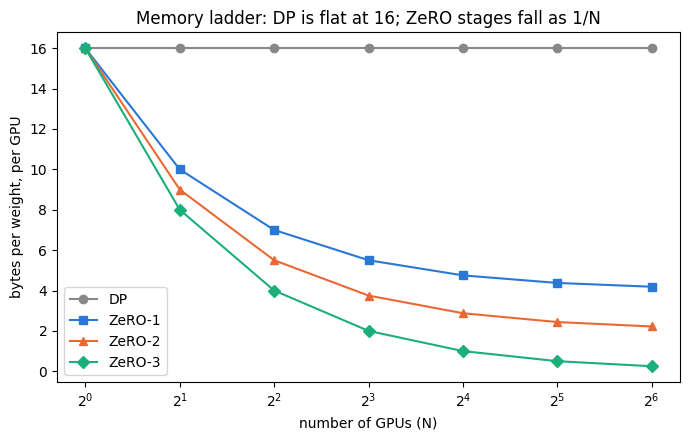

  wrote fig_memory_ladder.png
done — 32-GPU ZeRO simulation: memory measured, correctness proven, model trained.


In [8]:
print("=" * 70)
print("(5) MEMORY LADDER — bytes/weight/GPU vs number of GPUs")


def bpw(stage, n):
    return {DP: 16.0, Z1: 4 + 12 / n, Z2: 2 + 14 / n, Z3: 16 / n}[stage]

ns = [1, 2, 4, 8, 16, 32, 64]
print(f"  {'N':>4}" + "".join(f"{s:>10}" for s in STAGES))
for n in ns:
    print(f"  {n:>4}" + "".join(f"{bpw(s, n):>10.2f}" for s in STAGES))

GB = 80
BIG_P = 7e9                                 # a 7B-parameter model
print(f"\n  for a {BIG_P/1e9:.0f}B model, params that FIT in training state on one {GB} GB GPU:")
for stage in STAGES:
    b = bpw(stage, N_GPU)
    fit = GB * 1e9 / b
    print(f"    {stage:<8} {b:>6.2f} bytes/wt  ->  {fit/1e9:>6.1f}B params  "
          f"({'fits' if fit >= BIG_P else 'does NOT fit'} the {BIG_P/1e9:.0f}B model at N={N_GPU})")

plt.figure(figsize=(7, 4.5))
markers = {DP: "o", Z1: "s", Z2: "^", Z3: "D"}
col = {DP: "#888888", Z1: "#2a78d6", Z2: "#eb6834", Z3: "#1baf7a"}
for stage in STAGES:
    plt.plot(ns, [bpw(stage, n) for n in ns], marker=markers[stage],
             color=col[stage], label=stage)
plt.xscale("log", base=2); plt.xlabel("number of GPUs (N)")
plt.ylabel("bytes per weight, per GPU")
plt.title("Memory ladder: DP is flat at 16; ZeRO stages fall as 1/N")
plt.legend(); plt.tight_layout(); plt.savefig("fig_memory_ladder.png", dpi=110); plt.show()
print("  wrote fig_memory_ladder.png")

print("=" * 70)
print("done — 32-GPU ZeRO simulation: memory measured, correctness proven, model trained.")